# Causal Inference through Matching

*The art of putting people into boxes...for science.*

This lesson has four goals:
- Introduce the [Matched Pairs Procedure](#Matched-Pairs)
- Introduce the [Curse of Dimensionality and Propensity Score Matching](#Curse-of-Dimensionality) 
- Discuss the need for [Common Support](#Common-Support)
- Discuss [Matched Pairs Weighting Procedures](#Weighting)
    
In the last lesson, we learned about the Conditional Independence Assumption (CIA), and discussed how to construct a regression with a causal interpretation. However, data scientists often chafe at using regression models due to their assumption of linearity. One alternative to regression analysis that still fits well within the context of our previous lessons is matching. Matching is nice because we can avoid any assumptions about the functional form of our model. However, matching procedures come with their own set of dangers we must guard against -- many of which are glossed over or ignored by inexperienced practitioners. By the end of this lesson you should not only have a better understanding of how to implement and interpret matching techniques, but how to determine if they are appropriate in the first place.

<a id='Matched-Pairs'></a>
## The Matched Pairs Procedure

The matched pairs procedure is appealingly simple: it operates by examining individuals who have the same values of your covariates ($X_{i}$), but different treatment statuses ($D_{i}$). This allows you to compute a causal effect for each matched pair. In turn, you can compute population-weighted averages of matched pair effects to find the ATE ($E[Y_{1i} - Y_{0i}]$), or treatment group-weighted averages of matched pair effects to find the ATT ($E[Y_{1i} - Y_{0i} \text{ } | \text{ } D_{i} = 1]$). 

Matched pairs are also a nice follow up to our discussion about causal inference in regression analysis because these comparisons rely on the Conditional Independence Assumption in order to be considered causal. You'll need to go through the same thought process that we used when creating DAGs when you put together your list of covariates that you use for matched pairs. Remember, this means that you'll need to avoid using any bad controls when you create matched pairs.

To understand how matched pairs work, let's go through a simple example. Let's suppose that we are trying to figure out how effective our app is at building customer value ($D_{i} = 1$ if the customer has the app, $D_{i} = 0$ otherwise). Suppose we think that app adoption is as good as randomly assigned once we condition on age, but that older customers are less likely to have the app than young customers. If customers of different ages also have different untreated outcomes, then we have a selection bias issue (i.e., the difference between the observed outcome for app users and non-app users will not have a causal interpretation).

To keep things simple for this example, let's suppose we measure age as a categorical variable with two equally sized groups: old ($O$) and young ($Y$). Let's further suppose the following:
\begin{align*}
    Pr(D = 1 \text{ }|\text{ } X = O) &= 0.4 \\
    Pr(D = 1 \text{ }|\text{ } X = Y) &= 0.6 \\
    E[Y_{0i} \text{ } | \text{ }X = O] &= 40 \\
    E[Y_{0i} \text{ } | \text{ }X = Y] &= 20 \\
    Y_{i1} - Y_{i0} &= 10 \text{ }\forall \text{ }i
\end{align*}

In words, the above says three things:
- Our app-users have a 60-40 split between young and old inviduals, respectively (this follows from the fact that our two age groups are equally sized).
- Old and young individuals have average untreated outcomes of 40 and 20, respectively. We're being agnostic about what the units mean here, but if it helps then you can consider it to be monthly profit margin.
- The true effect of the app is to increases customer value by 10. This effect occurs for _everybody_.

Let's start by verifying that selection bias is present in this example. To see this, let's imagine that there are an equal number of individuals in our treatment and control groups. In this case, we'll have the following:
\begin{align*}
    E[Y_{1i} \text{ } | \text{ }D = 1] &= (0.6) \times (30) + (0.4) \times (50) = 38 \\
    E[Y_{0i} \text{ } | \text{ }D = 0] &= (0.4) \times (20) + (0.6) \times (40) = 32 \\
    \text{Observed Difference} &= E[Y_{1i} \text{ } | \text{ }D = 1] - E[Y_{0i} \text{ } | \text{ }D = 0] = 6
\end{align*}

Because younger individuals are more likley to use the app but have a lower expected $Y_{0}$, we end up with negative selection bias. This is a succinct (and slightly technical) way of saying that our control group has a disproportionately large number of customers that have high value (relative to the treatment group), so our comparison understates the true value of the app. In this case our comparison suggests that the app increases customer value by 6, rather than 10.

If we did want to calculate the true effect of our app, the matching procedure says that we could do so by comparing outcomes of customers with the same values of $X_{i}$. Remember, this relies on the CIA; if we don't believe that treatment is as good as randomly assigned once we condition on our covariates, we can't make the case for causality. Still, in this simple example, we would find the treatement effect for older customers as follows:
\begin{align*}
    E[Y_{1i} \text{ } | \text{ }D = 1, X_{i} = O] &= 50 \\ 
    E[Y_{0i} \text{ } | \text{ }D = 1, X_{i} = O] = E[Y_{0i} \text{ } | \text{ }D = 0, X_{i} = O] &= 40 \\
    \text{Average Effect}_{O} = E[Y_{1i} - Y_{0i} \text{ } | \text{ }D = 1, X_{i} = O] &= 10
\end{align*}

Similarly, we would find the treatment effect for young customers as follows:
\begin{align*}
    E[Y_{1i} \text{ } | \text{ }D = 1, X_{i} = Y] &= 30 \\ 
    E[Y_{1i} \text{ } | \text{ }D = 1, X_{i} = Y] = E[Y_{0i} \text{ } | \text{ }D = 0, X_{i} = Y] &= 20 \\
    \text{Average Effect}_{Y} = E[Y_{1i} - Y_{0i} \text{ } | \text{ }D = 1, X_{i} = Y] &= 10
\end{align*}

Using these two treatment effects, we could estimate the ATE or the ATT. The ATT is most straightforward within the context our example, so let's start there. We know that 40% of the treatment group is old and 60% is young. Therefore, we calculate the ATT as $(0.4) * (10) + (0.6) * (10) = 10$. To calculate the ATE _for our sample_, we would need to know what proportion of the sample is young or old. Earlier we assumed that half of our sample population is young and half is old. We could thus calculate the ATE as $(0.5) * (10) + (0.5) * (10) = 10$.

In this case the ATE and ATT are the same because we assumed everyone, young or old, had the same effect of treatment. In practice, treatment effect will usually vary across different types of individuals, and the ATE and ATT will be different. To see this, you can reconsider the above calculations for the ATE and ATT when but with the following treatment effects for old and young individuals: $E[Y_{i1} - Y_{i0} \text{ } | \text{ } X_{i} = O] = 15$ and $E[Y_{i1} - Y_{i0} \text{ } | \text{ } X_{i} = Y] = 5$.

Finally, to make sure you understand the difference between the ATE and ATT, let's try to come up with business scenarios in which we would want to estimate either quantity. The ATT might be useful if we wanted to estimate the increase in customer value we experienced after implementing our app. On the other hand, the ATE could be useful for what-if analyses; for example, it would be used to estimate how much we would increase customer value if we were able to encourage app use equally across all groups in our sample.

<a id='Curse-of-Dimensionality'></a>
## The Curse of Dimensionality and Propensity Score Matching

In practice, matching will not be as simple as the toy example we just explored. First of all, matching only really works when your $X$ variables are discrete; otherwise, the probability of exactly matching any two observations is 0. But even discrete variables can be hard to match. Consider what would happen in our toy example if we instead described customers' ages in years, as opposed to the "young" and "old" categories. We would immediately have dozens of categories to match across -- one for each age (in years) in our sample. That's a lot of matching, and there's no guarantee that we'll have both treated and untreated observations for each age. This is potentially a problem for calculating the ATT (ATE); if you can't match across all categories in the treatment group (full sample), you can't compute the average treatement effect on the treated (average treatment effect).

This problem of too many categories gets much worse once we start adding more controls to our matching procedure. So much worse in fact that it gets its own name: the curse of dimensionality. The curse of dimensionality says that the number of matches we need to make grows exponentially with the number of control variables we're using. To see this in action, it's easiest to imagine adding a series of dummy variables as controls, and then implementing matching. When implementing matching using only a single dummy variable control, as in our toy example earlier, there are only two groups for which we need matched and unmatched pairs. But if we were to add a second dummy variable, this would grow to four groups ($2 \times 2$). If we were to add a third, it would grow to eight groups ($2 \times 2 \times 2$), and so on. By the time we had 10 dummy variables, we would need to have matched treated and untreated observervations across 1024 groups ($2^{10}$). And that's just considering dummy variables -- imagine what would happen if some of our variables had many categories (e.g., age measured by decade of birth)!

The curse of dimensionality usually prevents us from implementing the standard matching procedure. As a workaround, we can instead use a technique called propensity score matching. Propensity score matching combines all our covariates into a single index, which is the propensity any given observation is treated ($Pr(D_{i} = 1| X_{i})$). We can then discretize our propensity scores by creating groups with similar values. Observations are considered "matched" within each group.

Propensity score matching still relies on the same assumptions as standard matching; that is, it requires the CIA. The idea here is that if the CIA holds for the standard matching technique using untransformed covariates, it will also hold for a matching technique using a propensity score generated by those same covariates. Stated formally:

\begin{equation*}
    \{Y_{0i}, Y_{1i}\} \perp\!\!\!\!\!\perp  D_{i} | X_{i} \implies \{Y_{0i}, Y_{1i}\} \perp\!\!\!\!\!\perp  D_{i} | Pr(X_{i})
\end{equation*}

Typically, economists have used either probit or logit models to estimate propensity scores. Lately, more sophisiticated machine learning methods have been utilized as well. This seems reasonable to me, and I can imagine that the propensity scores generated by newer methods are likely to be more accurate than those produced by, say, logit models. In general, the more accurate your propensity scores, the more accurate your estimated effects will be.

<a id='Common-Support'></a>
## Look Before You Leap: Check for Common Support Before Reporting Results

Before you start using your newly generated propensity scores to calculate treatment effects, you should double check that you have enough observations with similar scores to make credible comparisons. After all, the point of matching procedures is to compare individuals with similar x values. In turn, we need to observe both treated and untreated outcomes with similar propensity scores. Stated mathematically, we need the following to be true:

\begin{equation*}
    Pr(D=1 | X) < 1 \text{ } \forall \text{ } X
\end{equation*}

This just means there is no value of $X$ for which we could never observe an untreated observation, given a large enough sample size. In order to gut check this requirement, a straightforward method is to create two histograms of the distribution of treated and untreated groups across their predicted propensities. Often, these distributions will be skewed depending on whether they correspond to the treated on untreated group. In and of itself, this isn't a problem. After all, these groups are treated or untreated for a reason; the treated group is likely to have higher propensities that the untreated group, on average. However, there should be enough overlap that you can compare outcomes for any given propesnity level. 

We call this overlap __"common support,"__ and it is required to make credible causal inferences when utilizing propensity score matching. If you find that you have a common support problem, you simply may not be able to answer the research question at hand using matching. However, if the problem is mild, it may be manageable. In practice, the most straightforward way to deal with poor common support is to "trim" observations at either end of your propensity score range. This means dropping observations with propensity scores higher or lower than some threshold. Still, trimming  comes with a few caveats:
- Trimming can throw out useful information near the boundary of whatever threshold you choose. Trimmed observations that are close to threshold might have been good comparisons for observations that are also close to the threshold, but survive the trimming.
- Trimming cannot address common support problems in the interior of your distribution(s).
- Trimming makes it unclear what you are estimating. You are no longer estimating the ATT if you omit portions of the treatment group from your comparison.

Lastly, the two graphs below showcase two examples of "poor" and "good" common support, respectively. These examples are exaggerated so that they make clear the issue of common support. Still, as far as I'm aware, there aren't any theoretical justifications for what level of common support is "good enough." In practice you're data might not be as clear cut as these examples, and you'll have to decide for yourself whether you have enough treated and untreated observations across propensity scores to make valid comparisons.

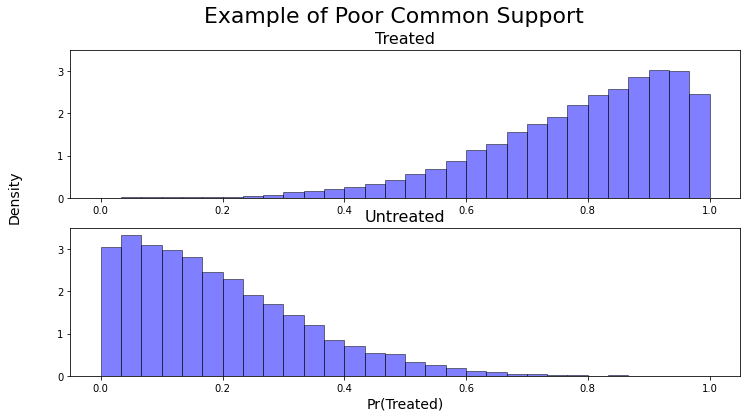

In [325]:
import numpy as np
from scipy.stats import skewnorm
import matplotlib.pyplot as plt

numValues = 10000
maxValue = 100
skewness1 = -100   # Negative values are left skewed, positive values are right skewed.
skewness2 = 100   

random1 = skewnorm.rvs(a=skewness1, loc=maxValue, size=numValues)  # Skewnorm function
random2 = skewnorm.rvs(a=skewness2, loc=maxValue, size=numValues)  # Skewnorm function

random1 = random1 - min(random1)      # Shift the set so the minimum value is equal to zero.
random1 = random1 / max(random1)      # Standardize all the vlues between 0 and 1. 
# random1 = random1 * maxValue          # Multiply the standardized values by the maximum value.

random2 = random2 - min(random2)      # Shift the set so the minimum value is equal to zero.
random2 = random2 / max(random2)      # Standardize all the vlues between 0 and 1. 

#Plot histogram to check skewness
fig,ax = plt.subplots(nrows=2, ncols=1, sharey=True)
fig.set_size_inches(12,6)
# fig1 = plt.hist(random1,30,density=True, color = 'blue', alpha=0.3)
ax[0].hist(random1,30,density=True, color='blue', alpha=0.5, edgecolor='black')
ax[0].set_title('Treated', fontsize=16)
ax[1].hist(random2,30,density=True, color='blue', alpha=0.5, edgecolor='black')
ax[1].set_title('Untreated', fontsize=16)
plt.xlabel(xlabel='Pr(Treated)', fontsize=14)
fig.text(0.06, 0.54, 'Density', ha='center', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Example of Poor Common Support', fontsize=22)
plt.show()

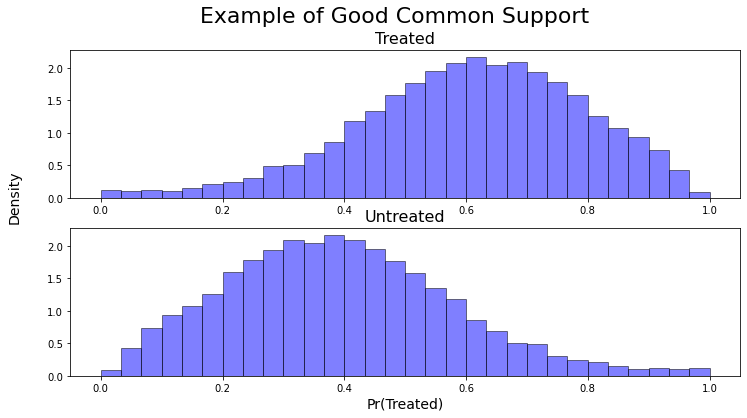

In [329]:
random1 = skewnorm.rvs(a=-2, loc=100, scale=100, size=10000)  # Skewnorm function
random2 = skewnorm.rvs(a=-2, loc=100, scale=100, size=10000)  # Skewnorm function

random1 = random1 - min(random1)      # Shift the set so the minimum value is equal to zero.
random1 = random1 / max(random1)      # Standardize all the vlues between 0 and 1. 
# random1 = random1 * maxValue          # Multiply the standardized values by the maximum value.

random2 = random2 - min(random2)      # Shift the set so the minimum value is equal to zero.
random2 = random2 / max(random2)      # Standardize all the vlues between 0 and 1. 

# adding distributions with different sizes/skewness to get the output I want (this is ugly)
random2 = skewnorm.rvs(a=-10, loc=maxValue, scale=100, size=6000) 
random2 = random2 - min(random2)     
random2 = random2 / max(random2) 

random3 = skewnorm.rvs(a=1, loc=maxValue, scale=100, size=6000) 
random3 = random3 - min(random3)     
random3 = random3 / max(random3) 

random4 = np.random.uniform(low=0, high=0.3, size=750)

# appending distributions to be graphed
test1 = np.append(random1, random2)
test1 = np.append(test1, random3)
test1 = np.append(test1, random4)

test2 = test1*(-1)+1

#Plot histogram to check skewness
fig,ax = plt.subplots(nrows=2, ncols=1, sharey=True)
fig.set_size_inches(12,6)
# fig1 = plt.hist(random1,30,density=True, color = 'blue', alpha=0.3)
ax[0].hist(test1,30,density=True, color='blue', alpha=0.5, edgecolor='black')
ax[0].set_title('Treated', fontsize=16)
ax[1].hist(test2,30,density=True, color='blue', alpha=0.5, edgecolor='black')
ax[1].set_title('Untreated', fontsize=16)
plt.xlabel(xlabel='Pr(Treated)', fontsize=14)
fig.text(0.06, 0.54, 'Density', ha='center', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Example of Good Common Support', fontsize=22)
plt.show()

<a id='Weighting'></a>
## Matched Pairs Weighting Procedures

After you've surpassed any potential common support issues, you should decide how you want to weight observations when computing treatment effects. Again, the inspiration for matching is that we want to compare treated and untreated outcomes that are "close" to one another. This forces us to define what we mean by "close." Moreover, if there are multiple observations "close" to one another, we need to decide if we want to emphasize certain comparisons within that grouping. 

I list several weighting options below, though there may be newer/different options available at this point. Here's a [link](https://arxiv.org/pdf/1010.5586.pdf) to a paper that summarizes the state of the matching literature circa 2010, and discusses several of the methods below. Of course, you can use any combination of these methods to gut check your results; if matching is a good method for your problem, you'll likely get similar results across multiple specifications.

#### Interval Matching

Interval matching is pretty straightforward, and its intuition aligns with the common support graphs above. With this method, you discretize your propensity distribution into intervals (i.e., bins), just like we did in the common support graphs. You then calculate the average treated and untreated outcome within each intervale, and take their difference. This is equivalent to equally weighting treated and untreated observations within eaach interval, and assigning no weight to all other observations.

#### Nearest Neighbor Matching

Nearest neighbor matching is also straightforward. For each treated observation, you find the closest untreated observation and assign it a weight of one. All other observations receive zero weight. This can be done with or without replacement, though the former is more common. If doing nearest neighbor matching with replacement, it can be helpful to double check that you are not re-using the same untreated observation(s) for many comparisons. If you're re-using the same observation(s) over and over as a counterfactual, it can be a sign that you lack common support.

#### Kernel Matching

Kernel matching uses "local" averages of untreated observations to make comparisons, where more weight is given to observations that are closer. Weights are given by
\begin{equation*}
    w(i,j) = \frac{G_{ij}}{\Sigma_{k\in{D_{k=0}}}G_{ik}}\\
    G_{ij} = G\left(\frac{P(X_{i}) - P(X_{k})}{a_{n}}\right)
\end{equation*}
$G$ is a kernel and $a_{n}$ is a bandwidth that gets smaller with the sample size. Depending on the kernel, all observations in $[0, 1]$ may receive weight.

#### Inverse Probability Matching

Inverse probability matching compares the treated mean to the counterfactual mean using a weighting scheme. Computing the former is straightforward, given your data. Computing the latter is done using the following:
\begin{equation}
    \frac{1}{n_{0}} \Sigma_{i}^{n_{0}}\frac{\hat{P}(X_{i})}{1-\hat{P}(X_{i})}Y_{i}
\end{equation}

This method favors untreated observations with high propensity scores, and downweights observations with low propensity scores. This ensures that observations we are unlikely to have obtained should be emphasized (e.g., observations that were likely to be treated, but nevertheless remained untreated), since they contain valuable information but do not often occur naturally in the data.

## Conclusion

Matching is a straightforward way to address causal inference issues, but we should be careful not to abuse it. It requires basically the same assumptions as causal inference in regression analysis (namely, the CIA), but does not make any linearity assumptions. 

When utilizing matching, you'll usually want to rely on some variant of propensity score matching. When doing this, you'll need to check that you have good common support and adjust your data as necessary. If you don't have common support, you may need to search for other options. 

Finally, you'll need to decide how to weight your treated-untreated comparisons. Some weighting schemes are more straightforward than others, but may produce less accurate treatment effect estimates.